In [4]:
import numpy as np
import pandas as pd

In [4]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'

In [5]:
!wget -P datasets/ $data 

--2026-09-27 17:27:43--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1475504 (1.4M) [text/plain]
Saving to: ‘datasets/data.csv.1’

data.csv.1          100%[===================>]   1.41M  2.58MB/s    in 0.5s    

2026-09-27 17:27:45 (2.58 MB/s) - ‘datasets/data.csv.1’ saved [1475504/1475504]



In [37]:
df = pd.read_csv('datasets/data.csv')
df.columns = df.columns.str.lower().str.replace(' ', '_')
df['make'].str.lower().str.replace(' ', '_')

0            bmw
1            bmw
2            bmw
3            bmw
4            bmw
          ...   
11909      acura
11910      acura
11911      acura
11912      acura
11913    lincoln
Name: make, Length: 11914, dtype: str

In [38]:
strings = list(df.dtypes[df.dtypes == 'str'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [39]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [40]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [41]:
for col in df.columns:
    print(col)
    print(df[col].unique())
    print(df[col].nunique())
    print("\n\n")

make
<StringArray>
[          'bmw',          'audi',          'fiat', 'mercedes-benz',
      'chrysler',        'nissan',         'volvo',         'mazda',
    'mitsubishi',       'ferrari',    'alfa_romeo',        'toyota',
       'mclaren',       'maybach',       'pontiac',       'porsche',
          'saab',           'gmc',       'hyundai',      'plymouth',
         'honda',    'oldsmobile',        'suzuki',          'ford',
      'cadillac',           'kia',       'bentley',     'chevrolet',
         'dodge',   'lamborghini',       'lincoln',        'subaru',
    'volkswagen',        'spyker',         'buick',         'acura',
   'rolls-royce',      'maserati',         'lexus',  'aston_martin',
    'land_rover',         'lotus',      'infiniti',         'scion',
       'genesis',        'hummer',         'tesla',       'bugatti']
Length: 48, dtype: str
48



model
<StringArray>
[  '1_series_m',     '1_series',          '100',   '124_spider',
    '190-class',     '2_series',       

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

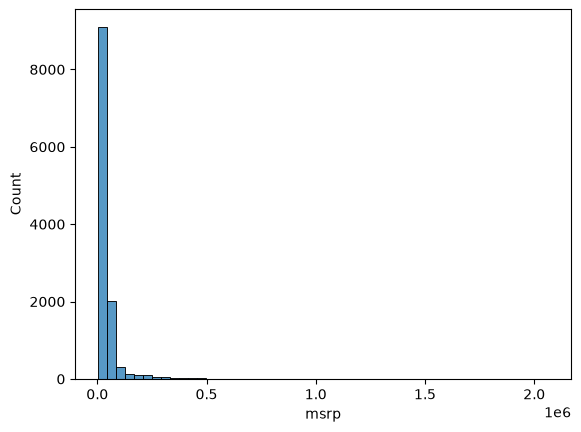

In [43]:
sns.histplot(df.msrp, bins = 50)

<Axes: xlabel='msrp', ylabel='Count'>

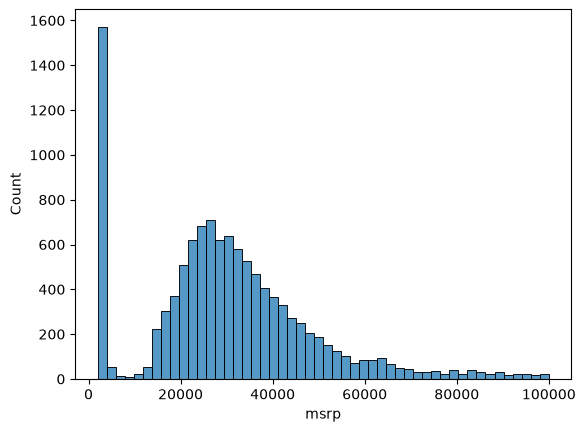

In [44]:
sns.histplot(df.msrp[df.msrp < 100000], bins = 50)
#the long tail will confuse the model and screw things up. We want to get rid of it, and the usual trick is to apply the logarithm to the price.

<Axes: xlabel='msrp', ylabel='Count'>

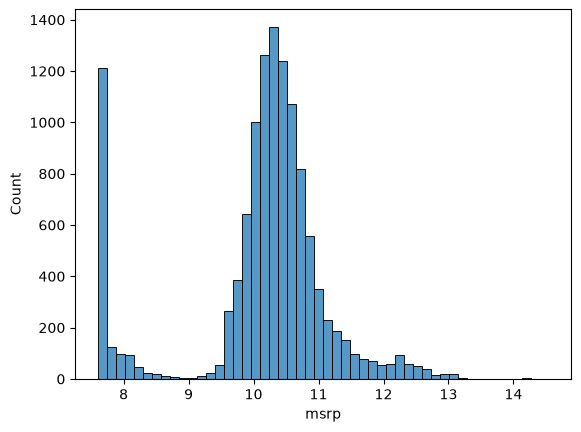

In [45]:
price_logs = np.log1p(df.msrp)
sns.histplot(price_logs, bins = 50)

In [46]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

In [47]:
cols = list(df.columns[df.isnull().sum() > 0])
            
def fill_na():
    for col in cols:
        mode = df[col].mode()[0]  # [0] lagana zaroori hai taaki scalar value mile
        df[col] = df[col].fillna(mode) # critical point


In [48]:
fill_na()
cols

['engine_fuel_type',
 'engine_hp',
 'engine_cylinders',
 'number_of_doors',
 'market_category']

In [49]:
df.isnull().sum()

make                 0
model                0
year                 0
engine_fuel_type     0
engine_hp            0
engine_cylinders     0
transmission_type    0
driven_wheels        0
number_of_doors      0
market_category      0
vehicle_size         0
vehicle_style        0
highway_mpg          0
city_mpg             0
popularity           0
msrp                 0
dtype: int64

In [50]:
n = len(df)

n_train = int(n * 0.6)
n_val = int(n * 0.2)
n_test = n - (n_val + n_train)

n, n_train, n_val, n_test

(11914, 7148, 2382, 2384)

In [51]:
df_train = df.iloc[:n_train]
df_val = df.iloc[n_train : n_train + n_val]
df_test = df.iloc[n_train + n_val:]

df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7143,mazda,navajo,1994,regular_unleaded,160.0,6.0,manual,rear_wheel_drive,2.0,crossover,compact,2dr_suv,19,14,586,2000
7144,mazda,navajo,1994,regular_unleaded,160.0,6.0,manual,rear_wheel_drive,2.0,crossover,compact,2dr_suv,19,14,586,2000
7145,mazda,navajo,1994,regular_unleaded,160.0,6.0,manual,four_wheel_drive,2.0,crossover,compact,2dr_suv,18,14,586,2000
7146,mazda,navajo,1994,regular_unleaded,160.0,6.0,manual,four_wheel_drive,2.0,crossover,compact,2dr_suv,18,14,586,2000


In [52]:
# you can see in the above output that the data is of only similar types or similar cars, thw better model will be the one that is trained using the mix or shuffle of the columns

idx = np.arange(n)

np.random.seed(42) # critical point
np.random.shuffle(idx)

idx


array([3995, 7474, 7300, ..., 5390,  860, 7270], shape=(11914,))

In [225]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train : n_train + n_val]]
df_test = df.iloc[idx[n_val + n_train :]]

In [226]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
3995,gmc,envoy_xl,2005,regular_unleaded,275.0,6.0,automatic,rear_wheel_drive,4.0,crossover,large,4dr_suv,18,13,549,29695
7474,volkswagen,passat,2016,regular_unleaded,170.0,4.0,automatic,front_wheel_drive,4.0,crossover,midsize,sedan,38,25,873,30495
7300,honda,odyssey,2016,regular_unleaded,248.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,passenger_minivan,28,19,2202,37650
3148,chevrolet,cruze,2015,regular_unleaded,138.0,4.0,manual,front_wheel_drive,4.0,crossover,midsize,sedan,36,25,1385,16170
747,volvo,740,1991,regular_unleaded,162.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",midsize,sedan,20,17,870,2000


In [227]:
len(df_train), len(df_val), len(df_test)

(7148, 2382, 2384)

In [228]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)



In [229]:
# now these values are the actual output values of the three parts of the datasets that we have created

y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

In [230]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

In [59]:
test = df_train.iloc[20]
test

make                         chevrolet
model                             aveo
year                              2009
engine_fuel_type      regular_unleaded
engine_hp                        107.0
engine_cylinders                   4.0
transmission_type               manual
driven_wheels        front_wheel_drive
number_of_doors                    4.0
market_category              hatchback
vehicle_size                   compact
vehicle_style            4dr_hatchback
highway_mpg                         34
city_mpg                            27
popularity                        1385
Name: 20, dtype: object

In [60]:
# let us take it as a test data and see how we are actually gonna proceed
# not considering vector for now just a basic terminology application about the values

def test_linear_regression(w0, w1, w2, w3):
    xi = [107, 34, 27] # consider these three parameters as the cost affecting parameters from the table

    w0 = w0 #initial bias
    wi = [w1, w2, w3]
    
    pred = w0
    
    for i in range(len(xi)):
        pred += wi[i]*xi[i]
    
    print(pred, y_train[20])

In [61]:
# one can see the difference is so huge
test_linear_regression(0, 1, 1, 1)

test_linear_regression(7.17, 0.01, 0.04, 0.002)
# so that gets u the importance of weights

168 9.55400099583723
9.654 9.55400099583723


In [62]:
#on ecan check the values
np.expm1(9.654), np.expm1(9.55400099583723)

(np.float64(15582.999596649986), np.float64(14099.999999999996))

In [63]:
#apply same thing on vector
def dot(xi, w):
    n = len(xi)
    res = 0.0
    for i in range(n):
        res += xi[i] * w[i]
    return res


def linear_regression(xi):
    return w0 + dot(xi, w)

xi = [107, 34, 27]
w = [0.01, 0.04, 0.002]
w0 = 7.17

linear_regression(xi)

9.654

In [64]:
# now move towards more real scenerios where the things are array of vectors or multidimensional matrix

w_new = [w0] + w

x1  = [1, 148, 24, 1385]
x2  = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

# 1 is added in first column just to make multiplication of w0 with 1 so that this won't get affected

X = [x1, x2, x10]
X = np.array(X)



In [65]:
def linear_regression(X):
    return X.dot(w_new)

linear_regression(X)

# so this is the way how we get the price of deifferent cars

array([12.38 , 13.552, 12.312])

In [66]:
# Training a linear regression model

X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]

X = np.array(X)
X

array([[ 148,   24, 1385],
       [ 132,   25, 2031],
       [ 453,   11,   86],
       [ 158,   24,  185],
       [ 172,   25,  201],
       [ 413,   11,   86],
       [  38,   54,  185],
       [ 142,   25,  431],
       [ 453,   31,   86]])

In [67]:
X = np.column_stack([ones, X])
X

array([[1.000e+00, 1.480e+02, 2.400e+01, 1.385e+03],
       [1.000e+00, 1.320e+02, 2.500e+01, 2.031e+03],
       [1.000e+00, 4.530e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 1.580e+02, 2.400e+01, 1.850e+02],
       [1.000e+00, 1.720e+02, 2.500e+01, 2.010e+02],
       [1.000e+00, 4.130e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 3.800e+01, 5.400e+01, 1.850e+02],
       [1.000e+00, 1.420e+02, 2.500e+01, 4.310e+02],
       [1.000e+00, 4.530e+02, 3.100e+01, 8.600e+01]])

In [74]:
y = [10000, 20000, 15000, 20050, 10000, 20000, 15000, 25000, 12000]

X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]

X = np.array(X)

# now since the inverse of those matrix which are not squared aren't possible so we use Gram Matrix Approximation

# XTX = X.dot(X.T) # that will result in a square matrix

X

array([[ 148,   24, 1385],
       [ 132,   25, 2031],
       [ 453,   11,   86],
       [ 158,   24,  185],
       [ 172,   25,  201],
       [ 413,   11,   86],
       [  38,   54,  185],
       [ 142,   25,  431],
       [ 453,   31,   86]])

In [73]:
ones = np.ones(len(X))
X = np.column_stack([ones, X])
X

array([[1.000e+00, 1.480e+02, 2.400e+01, 1.385e+03],
       [1.000e+00, 1.320e+02, 2.500e+01, 2.031e+03],
       [1.000e+00, 4.530e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 1.580e+02, 2.400e+01, 1.850e+02],
       [1.000e+00, 1.720e+02, 2.500e+01, 2.010e+02],
       [1.000e+00, 4.130e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 3.800e+01, 5.400e+01, 1.850e+02],
       [1.000e+00, 1.420e+02, 2.500e+01, 4.310e+02],
       [1.000e+00, 4.530e+02, 3.100e+01, 8.600e+01]])

In [70]:
XTX = X.T.dot(X)
XTX_inv = np.linalg.inv(XTX)
w_full = XTX_inv.dot(X.T).dot(y)

w0 = w_full[0]
w1 = w_full[1:]

print(w_full,"\n", w0,"\n", w1)

[ 2.58447541e+04 -1.60890647e+01 -1.99472549e+02 -1.22802883e+00] 
 25844.754055766753 
 [ -16.08906468 -199.47254894   -1.22802883]


In [75]:
# based on above methodology define a fucntion that matches with our linear_regression

def train_linear_regression(X, y):
    ones = np.ones(len(X))
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

w0, w = train_linear_regression(X, y)

print(w0,"\n",w)

# caution : u will going to encounter an error until u refresh the initial definition of "X", as the matrix is will considered to be singular until then

25844.754055766753 
 [ -16.08906468 -199.47254894   -1.22802883]


In [78]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

In [92]:
# Car price baseline model

base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']



In [182]:
X_train = df_train[base].values
w0, w = train_linear_regression(X_train, y_train)

X_val = df_val[base].values

y_pred = w0 + X_train.dot(w)

print(w0,"\n", w,"\n", y_pred)

8.252033042768588 
 [ 9.59230305e-03 -1.72294337e-01  1.60176345e-02  2.28213646e-03
 -2.13381678e-05] 
 [10.1624209   9.84064251 10.04202589 ...  9.49561928  9.96664322
  9.38542375]


<Axes: ylabel='Count'>

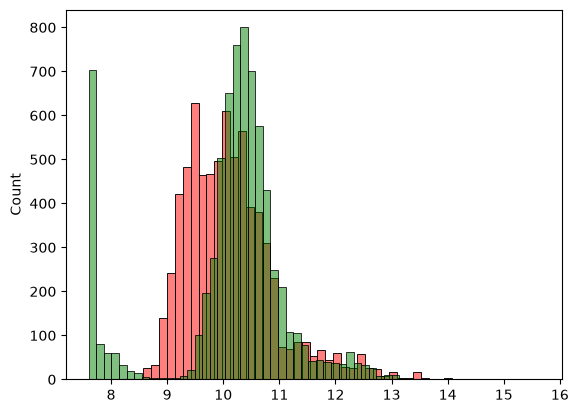

In [183]:
sns.histplot(y_pred, color = 'red', bins=50, alpha=0.5)
sns.histplot(y_train, color = "green", bins=50, alpha=0.5)

# so they are kinda accurate like overlapping but not that much...so need to reduce the error term, and lets take an error term te be RMSE

In [104]:
def rmse(y, y_pred):
    val = (y - y_pred) ** 2
    val = val.mean()
    return np.sqrt(val)

print(rmse(y_train, y_pred))

0.7522708393914287


In [105]:
# now the above rmse value(0.7522708393914287) is what we want to reduce to make our model more accurate...

# the process of using domain knowledge and raw data to create, transform, and select the input variables—called features—that machine learning models use to make predictions

# And hence here arrives FEATURE ENGINEERING

df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,gmc,envoy_xl,2005,regular_unleaded,275.0,6.0,automatic,rear_wheel_drive,4.0,crossover,large,4dr_suv,18,13,549
1,volkswagen,passat,2016,regular_unleaded,170.0,4.0,automatic,front_wheel_drive,4.0,crossover,midsize,sedan,38,25,873
2,honda,odyssey,2016,regular_unleaded,248.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,passenger_minivan,28,19,2202
3,chevrolet,cruze,2015,regular_unleaded,138.0,4.0,manual,front_wheel_drive,4.0,crossover,midsize,sedan,36,25,1385
4,volvo,740,1991,regular_unleaded,162.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",midsize,sedan,20,17,870


In [178]:
# one of the affecting factors I think is age too

def prepare_X(df):
    df = df.copy() # copy is made to not manipulate the contents of the original dataframe
    df['age'] = 2017 - df['year']
    features = base + ['age']
    X = df[features].values
    return X    

# df['year'].max() to know which one is the largest number of year

X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
print(w0)
print(w)
print(y_pred)


9.388158960982953
[ 3.85232165e-03  7.02144327e-02 -2.67640286e-03  7.07554621e-03
 -5.34297223e-05 -9.32001987e-02]
[ 9.22877964 10.41608826 10.49970643 ...  9.10130867 10.36315818
 10.99765971]


0.5087934437632957


<Axes: ylabel='Count'>

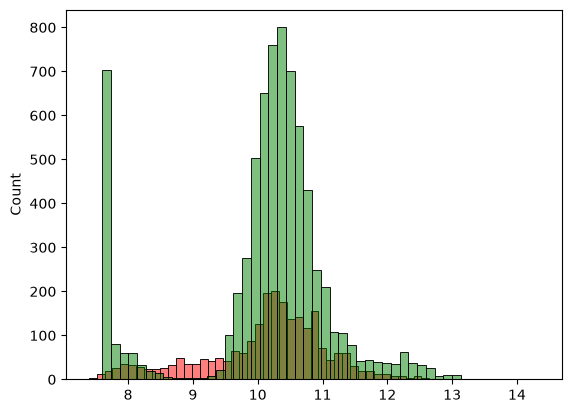

In [179]:
print(rmse(y_val, y_pred))
# an u can see a huge improvement here... in both values and the curve...

sns.histplot(y_pred, color = 'red', bins=50, alpha=0.5)
sns.histplot(y_train, color = "green", bins=50, alpha=0.5)

In [177]:
# and lets try to make more adjustments... we can focus on 1 more thing number of doors"

def prepare_X(df):
    df = df.copy() # copy is made to not manipulate the contents of the original dataframe
    df['age'] = 2017 - df['year']
    features = base + ['age']
    features.append('number_of_doors')
    X = df[features].values
    return X

X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

y_pred

print(rmse(y_val, y_pred))
# not musch improved


0.508472864633373


In [159]:
# Although for such cases "One-Hot Encoding" way is preferred and lets also look the categorical values:

categorical_columns = [
    'make', 'model', 'engine_fuel_type', 'driven_wheels', 'market_category',
    'vehicle_size', 'vehicle_style']

categorical = {}

for c in categorical_columns:
    categorical[c] = list(df_train[c].value_counts().head().index)
    # to get the most sold cars and the msot sold are the ones we required to train our model 

print(categorical)

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'], 'model': ['silverado_1500', 'tundra', 'f-150', 'sierra_1500', 'beetle_convertible'], 'engine_fuel_type': ['regular_unleaded', 'premium_unleaded_(required)', 'premium_unleaded_(recommended)', 'flex-fuel_(unleaded/e85)', 'diesel'], 'driven_wheels': ['front_wheel_drive', 'rear_wheel_drive', 'all_wheel_drive', 'four_wheel_drive'], 'market_category': ['crossover', 'flex_fuel', 'luxury', 'luxury,performance', 'hatchback'], 'vehicle_size': ['compact', 'midsize', 'large'], 'vehicle_style': ['sedan', '4dr_suv', 'coupe', 'convertible', '4dr_hatchback']}


In [160]:
def prepare_X(df):
    df = df.copy() # copy is made to not manipulate the contents of the original dataframe
    df['age'] = 2017 - df['year']
    features = base + ['age']

    for v in [2, 3, 4]:
        df['no_doors_%d' % v] = (df.number_of_doors == v).astype(int)
        features.append('no_doors_%d' % v)
        
    for name, values in categorical.items():
        for value in values:
            df['%s_%s' %(name, value)] = (df[name] == value).astype(int)
            features.append('%s_%s' %(name, value))

    df_num = df[features]
    X = df_num.values

    return X

X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

y_pred = w0 + X_train.dot(w)

print(rmse(y_train, y_pred))

390.17229091750687


y_train min/max: 7.601402334583733 14.349527179656565
y_pred min/max: -657.0 13713.0


<Axes: ylabel='Count'>

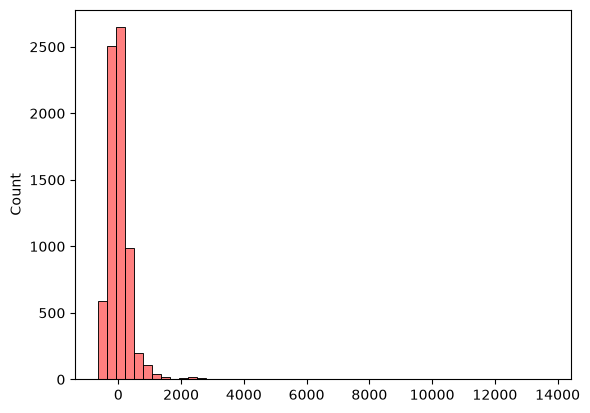

In [175]:
print("y_train min/max:", y_train.min(), y_train.max())
print("y_pred min/max:", y_pred.min(), y_pred.max())

sns.histplot(y_pred, color = "red", bins = 50, alpha = 0.5)
sns.histplot(y_train, color = "green", bins = 50, alpha = 0.5)


In [211]:
# for this overfitting we use Regularization(Ridge Regression)
# Here what we do is we nee to decrese the extent of duplicate columns and we can do so by adding some values in diagonal and another goal is to find the best suitable value to be added in the diagonal and that value is called Regularization Parameter


X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5.00000001],
]

X = np.array(X)
X
y= [1, 2, 3, 1, 2, 3]

In [212]:
XTX = X.T.dot(X)
XTX

array([[140.        , 111.        , 111.00000004],
       [111.        , 108.        , 108.00000005],
       [111.00000004, 108.00000005, 108.0000001 ]])

In [213]:
XTX_inv = np.linalg.inv(XTX)
XTX_inv

LinAlgError: Singular matrix

In [214]:
XTX = XTX + 0.01 * np.eye(3)
XTX

# that 0.01 is nothing but the regularization parameter

array([[140.01      , 111.        , 111.00000004],
       [111.        , 108.01      , 108.00000005],
       [111.00000004, 108.00000005, 108.0100001 ]])

In [215]:
XTX_inv = np.linalg.inv(XTX)
XTX_inv


array([[ 3.85624712e-02, -1.98159300e-02, -1.98158861e-02],
       [-1.98159300e-02,  5.00124975e+01, -4.99875026e+01],
       [-1.98158861e-02, -4.99875026e+01,  5.00124974e+01]])

In [234]:
def train_linear_regression_reg(X, y, r):
    ones = np.ones(len(X))
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r*np.eye(len(XTX))
    
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [240]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=0.01)
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
print(rmse(y_val, y_pred))

0.5087956421781555


In [263]:
#so accidently for our case things are not went much well as I think i replaced NaN values with 'mode' whearas if replaced by 0 then the resulting value would be around "0.4608208286209523"
# but may be we can imrove by changing "r"

# that one action is called tuning the model

r = 0.0
rmse_val = 0.5087956421781555

for r_val in [0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    w0,w = train_linear_regression_reg(X_train, y_train, r_val)
    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    if(rmse(y_val, y_pred) < rmse_val):
        r = r_val
        rmse_val = rmse(y_val, y_pred)
print(r, "\n")
w0, w = train_linear_regression_reg(X_train, y_train, r)
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
print(rmse(y_val, y_pred))

1e-05 

0.5087934459550957


In [271]:
# enough thing now, its time to finally use the model in test dataset

# combine the 2 dataframes df_train and df_val

df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop = True)

X_full_train = prepare_X(df_full_train)
X_full_train


y_full_train = np.concatenate([y_train, y_val])

w0,w = train_linear_regression_reg(X_full_train, y_full_train, r_val)
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

def find_best_r(X_tr, y_tr, X_v, y_v):
    best_r = 0.0
    min_rmse = float('inf')
    
    for r_val in [0.00001, 0.0001, 0.001, 0.1, 1, 10]:
        # Train data par model train karo
        w0, w = train_linear_regression_reg(X_tr, y_tr, r=r_val)
        
        # Validation data par predict karo
        y_pred_val = w0 + X_v.dot(w)
        current_rmse = rmse(y_v, y_pred_val)
        
        # Check karo agar yeh sabse accha hai
        if current_rmse < min_rmse:
            min_rmse = current_rmse
            best_r = r_val
            
    print(f"Best r mil gaya: {best_r} (Validation RMSE: {min_rmse})")
    return best_r

# Train aur Validation sets prepare karo (tuning ke liye)
X_train_set = prepare_X(df_train)
X_val_set = prepare_X(df_val)

# Best r find karo
best_r = find_best_r(X_train_set, y_train, X_val_set, y_val)

Best r mil gaya: 1e-05 (Validation RMSE: 0.5087934459550957)


In [274]:
X_test = prepare_X(df_test)
w0, w1 = train_linear_regression_reg(X_test, y_test, best_r)
y_pred = w0 + X_test.dot(w)
print(rmse(y_test, y_pred))


0.724365762776918


In [291]:
car = df_test.iloc[10].to_dict()
car

{'make': 'toyota',
 'model': 'previa',
 'year': 1995,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 161.0,
 'engine_cylinders': 4.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'all_wheel_drive',
 'number_of_doors': 3.0,
 'market_category': 'crossover',
 'vehicle_size': 'compact',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 20,
 'city_mpg': 15,
 'popularity': 2031}

In [292]:

def price_predictor(car, best_r):
    df_small = pd.DataFrame([car])
    X_small = prepare_X(df_small)
    y_pred = w0 + X_small.dot(w)
    y_pred = y_pred[0]
    return np.expm1(y_pred).item()

price = price_predictor(car, best_r)
print(price)
print(np.expm1(y_test[10]).item())

5695.487794861924
2194.0000000000005
